# **Analisis Perbandingan Metode Autocorrelation dan Fast Fourier Transform (FFT) Peak Detection untuk Pengenalan Nada Dasar Instrumen Musik Gitar**

**Mata Kuliah:** Pengolahan Sinyal Digital  
**Dataset:** Guitar Audio Dataset for Analysis (GADA) — 5 Model Gitar Listrik (`EpiSG`, `Gretsch`, `HBLP`, `HBStrat`, `HBTE52`)  

Notebook ini berisi implementasi lengkap alur Pengolahan Sinyal Digital (PSD) mulai dari pra-pemrosesan sinyal (*Band-Pass Filtering*, segmentasi *steady-state*, *Hamming Windowing*, penghapusan dengung 50 Hz & 100 Hz pada domain frekuensi, serta rekonstruksi IFFT), estimasi frekuensi dasar ($F_0$) menggunakan metode **FFT Peak Detection** dan **Autocorrelation**, visualisasi sinyal, hingga evaluasi massal pada **2.172 sampel audio gitar**.


In [1]:
import os
import re
import json
import time
import shutil
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import butter, lfilter, correlate
from sklearn.metrics import accuracy_score, confusion_matrix
from IPython.display import Audio, display

plt.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid")

In [2]:
# Deteksi otomatis lingkungan eksekusi (Google Colab atau Komputer Lokal)
try:
    import google.colab
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/PROJECT PSD"
    print("Lingkungan terdeteksi: Google Colab")
except ImportError:
    BASE_DIR = os.getcwd()
    print(f"Lingkungan terdeteksi: Lokal ({BASE_DIR})")

DATASET_DIR = os.path.join(BASE_DIR, "GUITAR")
SAMPLE_PATH = os.path.join(DATASET_DIR, "Gretsch", "Gretsch_C_open_122_ID1_1.wav")

if not os.path.exists(DATASET_DIR):
    raise FileNotFoundError(
        f"Folder dataset GUITAR tidak ditemukan di: {DATASET_DIR}\n"
        "Pastikan folder GUITAR berada di direktori kerja proyek."
    )

if not os.path.exists(SAMPLE_PATH):
    raise FileNotFoundError(f"File sampel tidak ditemukan: {SAMPLE_PATH}")

print(f"Dataset ditemukan : {DATASET_DIR}")
print(f"Sampel uji tunggal: {SAMPLE_PATH}")

Lingkungan terdeteksi: Lokal (D:\KULIAH SMT 3\PSD\PROJECT PSD)
Dataset ditemukan : D:\KULIAH SMT 3\PSD\PROJECT PSD\GUITAR
Sampel uji tunggal: D:\KULIAH SMT 3\PSD\PROJECT PSD\GUITAR\Gretsch\Gretsch_C_open_122_ID1_1.wav


# **Parameter Pengolahan Sinyal Digital**
Penentuan parameter mengikuti karakteristik akustik gitar standar dan kebutuhan penyaringan gangguan:
- **Laju Pencuplikan (`SR`)**: `22.050 Hz` (mampu menangkap frekuensi hingga batas Nyquist `11.025 Hz`).
- **Rentang Filter Band-Pass Butterworth (Orde 6)**: `50 Hz – 6.000 Hz` untuk mempertahankan nada dasar dan harmonik gitar sambil membuang noise frekuensi sangat rendah maupun sangat tinggi.
- **Frekuensi Dengung Listrik (`NOISE_FREQS`)**: `50 Hz` dan `100 Hz` (diredam manual pada domain frekuensi).
- **Rentang Nada Dasar Gitar**: `50 Hz – 1.200 Hz` sebagai batas pencarian puncak pada FFT maupun rentang *lag* pada Autokorelasi.


In [3]:
# Laju pencuplikan sinyal audio
SR = 22050  # Hz

# Parameter Band-Pass Filter Butterworth (Orde 6)
F_LOW_CUT = 50      # Hz
F_HIGH_CUT = 6000   # Hz
BUTTER_ORDER = 6

# Frekuensi gangguan listrik yang diredam (Notch manual)
NOISE_FREQS = [50, 100]  # Hz

# Rentang pencarian frekuensi dasar gitar
F_MIN_GUITAR = 50    # Hz
F_MAX_GUITAR = 1200  # Hz

# **Tahap 1: Penyaringan Band-Pass & Fungsi Pemetaan Nada**
Pada tahap ini dibuat filter *Band-Pass Butterworth* orde 6 serta fungsi pembantu untuk memetakan nama nada ke nada dasar (*root note* tanpa angka oktaf dan tanda kromatik) serta mengekstrak label kunci sebenarnya dari nama file dataset GADA.


In [4]:
def butter_bandpass(lowcut, highcut, fs, order=BUTTER_ORDER):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return b, a

def apply_bandpass(data, lowcut, highcut, fs, order=BUTTER_ORDER):
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    y = lfilter(b, a, data)
    return y

def get_note_only(note_with_octave):
    """Menghapus angka oktaf dan simbol (#/b) untuk memperoleh nama nada dasar."""
    if note_with_octave in ["N/A", "Error"]:
        return note_with_octave
    note_only = re.sub(r'-?\d+', '', note_with_octave)
    return note_only.replace("#", "").replace("b", "").replace("♯", "").replace("♭", "")

def ekstrak_label_asli(nama_file):
    """Mengekstrak nama akor dan nada dasar asli dari pola nama file dataset GADA."""
    bagian = os.path.splitext(nama_file)[0].split("_")
    akor = bagian[1]
    nada_dasar = akor.replace("m", "")
    return akor, nada_dasar

# **Tahap 2: Segmentasi, Hamming Windowing, FFT, Notch Filter & Rekonstruksi IFFT**
Tahapan pemrosesan inti meliputi:
1. Memuat sinyal audio dengan laju pencuplikan `22.050 Hz`.
2. Menerapkan filter *Band-Pass Butterworth* orde 6 (`50 – 6.000 Hz`).
3. Memotong segmen *steady-state* pada rentang waktu `0,3 – 0,8 detik` untuk menghindari lonjakan awal (*attack transient*) saat senar dipetik.
4. Menerapkan **Hamming Window** untuk mengurangi kebocoran spektrum (*spectral leakage*).
5. Mengubah sinyal ke domain frekuensi menggunakan **FFT**, kemudian meredam frekuensi gangguan `50 Hz` dan `100 Hz` **sebelum** menghitung magnitudo spektrum.
6. Merekonstruksi spektrum yang telah dibersihkan kembali ke domain waktu menggunakan **IFFT** sebagai masukan bersih untuk metode Autokorelasi.


In [5]:
def core_fft_ifft_processing(audio_file_path, sr=SR):
    # 1. Muat sinyal audio
    y_raw, sr = librosa.load(audio_file_path, sr=sr)

    # 2. Terapkan Band-Pass Filter Butterworth orde 6 (50 - 6000 Hz)
    y_filtered = apply_bandpass(y_raw, F_LOW_CUT, F_HIGH_CUT, sr, order=BUTTER_ORDER)

    # 3. Segmentasi bagian steady-state (0.3 detik - 0.8 detik)
    idx_mulai = int(0.3 * sr)
    idx_selesai = min(int(0.8 * sr), len(y_filtered))
    y_segment = y_filtered[idx_mulai:idx_selesai]

    # 4. Terapkan Hamming Window untuk menekan spectral leakage
    window = np.hamming(len(y_segment))
    y_windowed = y_segment * window

    # 5. Transformasi ke domain frekuensi (FFT)
    fft_spectrum = np.fft.fft(y_windowed)
    N = len(y_segment)
    frequencies = np.fft.fftfreq(N, d=1/sr)

    # 6. Reduksi noise spesifik pada 50 Hz dan 100 Hz sebelum magnitudo dihitung
    for noise_freq in NOISE_FREQS:
        idx = np.argmin(np.abs(frequencies - noise_freq))
        if 1 < idx < N // 2:
            fft_spectrum[idx - 1 : idx + 2] *= 0.01
            fft_spectrum[-idx - 1 : -idx + 2] *= 0.01

    # Hitung spektrum magnitudo bersih
    fft_result = np.abs(fft_spectrum)

    # 7. Rekonstruksi kembali ke domain waktu (IFFT)
    y_ifft_segment = np.fft.ifft(fft_spectrum).real

    return {
        "y_raw": y_raw,
        "y_filtered": y_filtered,
        "y_segment": y_segment,
        "y_windowed": y_windowed,
        "fft_result": fft_result,
        "frequencies": frequencies,
        "y_ifft_segment": y_ifft_segment,
        "N": N,
        "sr": sr
    }

# **Tahap 3: Deteksi Nada Dasar (FFT Peak Detection & Autocorrelation)**
Kedua metode bekerja pada domain yang berbeda:
- **FFT Peak Detection (Domain Frekuensi)**: Mencari bin frekuensi dengan magnitudo energi tertinggi dalam rentang `50 – 1.200 Hz`.
- **Autocorrelation (Domain Waktu)**: Menghitung kemiripan sinyal bersih hasil rekonstruksi IFFT terhadap dirinya sendiri pada berbagai pergeseran waktu (*lag* $\tau$), mencari puncak utama pada rentang lag `sr/1200` hingga `sr/50`, lalu menghitung $F_0 = f_s / \tau_{peak}$.
- **Pengecekan Hubungan Harmonik (`is_harmonic_of`)**: Digunakan untuk mengidentifikasi apakah selisih estimasi kedua metode disebabkan oleh kelipatan harmonik atau kesalahan oktaf.


In [6]:
def fft_peak_f0_segment(fft_result, frequencies, fmin=F_MIN_GUITAR, fmax=F_MAX_GUITAR):
    # Ambil hanya komponen frekuensi positif pada rentang gitar
    mask = (frequencies >= fmin) & (frequencies <= fmax)
    freq_band = frequencies[mask]
    spec_band = fft_result[mask]

    if len(spec_band) == 0:
        return 0.0

    idx = np.argmax(spec_band)
    return float(freq_band[idx])

def pitch_detection_autocorr_stable(y_clean_segment, sr=SR):
    try:
        segment = y_clean_segment - np.mean(y_clean_segment)
        if np.allclose(segment, 0):
            return 0.0, "Error", "Error"

        # Hitung Autocorrelation (identik secara matematis dengan np.correlate, lebih cepat via FFT)
        acf_full = correlate(segment, segment, mode='full', method='fft')
        acf = acf_full[len(acf_full) // 2 :]

        # Tentukan batas lag berdasarkan rentang frekuensi gitar (50 - 1200 Hz)
        lag_min = int(sr / F_MAX_GUITAR)
        lag_max = min(int(sr / F_MIN_GUITAR), len(acf))

        acf_range = acf[lag_min:lag_max]
        peak_lag = int(np.argmax(acf_range)) + lag_min

        # Konversi lag puncak ke frekuensi fundamental (Hz)
        f0 = float(sr / peak_lag)

        # Pemetaan frekuensi ke notasi musik
        note = librosa.hz_to_note(f0)
        return f0, get_note_only(note), note

    except Exception:
        return 0.0, "Error", "Error"

def get_autocorr_curve(y_clean_segment, sr=SR):
    """Mengembalikan kurva autokorelasi ternormalisasi untuk keperluan visualisasi."""
    segment = y_clean_segment - np.mean(y_clean_segment)
    acf_full = correlate(segment, segment, mode='full', method='fft')
    acf = acf_full[len(acf_full) // 2 :]
    if acf[0] != 0:
        acf = acf / acf[0]
    return acf

def is_harmonic_of(f_big, f_small, tol_rel=0.06, max_k=5):
    if f_small <= 0 or f_big <= 0:
        return False, None
    ratio = f_big / f_small
    k = int(round(ratio))
    if k < 2 or k > max_k:
        return False, None
    if abs(ratio - k) <= tol_rel:
        return True, k
    return False, None

# **Tahap 4: Pengujian Sampel Tunggal & Visualisasi Tahapan DSP**
Pada bagian ini dilakukan pengujian pada satu file audio gitar (`Gretsch_C_open_122_ID1_1.wav`) sekaligus menampilkan visualisasi lengkap dari seluruh tahapan pemrosesan sinyal digital:
1. Perbandingan gelombang domain waktu asli (*raw*) dan hasil filter *Band-Pass*.
2. Perbandingan segmen setelah *Hamming Window* dan hasil rekonstruksi bersih *IFFT*.
3. Spektrum magnitudo FFT beserta puncak frekuensi dominan yang terdeteksi.
4. Kurva Autokorelasi beserta penanda titik puncak *lag* periode dasar.


In [7]:
def compare_single_sample_improved(sample_path):
    if not os.path.exists(sample_path):
        print("File tidak ditemukan:", sample_path)
        return None

    nama_file = os.path.basename(sample_path)
    akor_asli, root_asli = ekstrak_label_asli(nama_file)
    print(f"Menganalisis file : {nama_file}")
    print(f"Label Sebenarnya  : Akor {akor_asli} (Nada Dasar: {root_asli})")

    hasil = core_fft_ifft_processing(sample_path, sr=SR)

    # Deteksi Pitch FFT Peak Detection
    t0 = time.perf_counter()
    f0_fft = fft_peak_f0_segment(hasil["fft_result"], hasil["frequencies"], fmin=F_MIN_GUITAR, fmax=F_MAX_GUITAR)
    waktu_fft_ms = (time.perf_counter() - t0) * 1000

    # Deteksi Pitch Autocorrelation (menggunakan sinyal bersih rekonstruksi IFFT)
    t0 = time.perf_counter()
    f0_ac, nada_ac, note_ac_full = pitch_detection_autocorr_stable(hasil["y_ifft_segment"], hasil["sr"])
    waktu_ac_ms = (time.perf_counter() - t0) * 1000

    if f0_fft > 0:
        note_fft_full = librosa.hz_to_note(f0_fft)
        note_fft = get_note_only(note_fft_full)
    else:
        note_fft_full, note_fft = "N/A", "N/A"

    # Cek hubungan harmonik / oktaf antara hasil kedua metode
    f_tinggi, f_rendah = max(f0_fft, f0_ac), min(f0_fft, f0_ac)
    is_harm, kelipatan = is_harmonic_of(f_tinggi, f_rendah)
    ket_harmonik = f"Ya (kelipatan ke-{kelipatan})" if is_harm else "Tidak ada perbedaan harmonik"

    df = pd.DataFrame({
        "Metode": ["FFT Peak Detection", "Autocorrelation (Input IFFT)"],
        "F0 (Hz)": [round(f0_fft, 2), round(f0_ac, 2)],
        "Nada Dasar": [note_fft, nada_ac],
        "Notasi Lengkap": [note_fft_full, note_ac_full],
        "Status vs Label Asli": [
            "Benar" if note_fft == root_asli else "Meleset",
            "Benar" if nada_ac == root_asli else "Meleset"
        ],
        "Waktu Proses (ms)": [round(waktu_fft_ms, 3), round(waktu_ac_ms, 3)]
    })
    display(df)
    print(f"Analisis Hubungan Harmonik antar Metode: {ket_harmonik}")
    return hasil, f0_fft, f0_ac, note_fft_full, note_ac_full

hasil_tunggal, f0_fft_s, f0_ac_s, note_fft_s, note_ac_s = compare_single_sample_improved(SAMPLE_PATH)

Menganalisis file : Gretsch_C_open_122_ID1_1.wav
Label Sebenarnya  : Akor C (Nada Dasar: C)


,Metode,F0 (Hz),Nada Dasar,Notasi Lengkap,Status vs Label Asli,Waktu Proses (ms)
0,FFT Peak Detection,130.00,C,C3,Benar,0.104
1,Autocorrelation (Input IFFT),132.04,C,C3,Benar,18.471


Analisis Hubungan Harmonik antar Metode: Tidak ada perbedaan harmonik


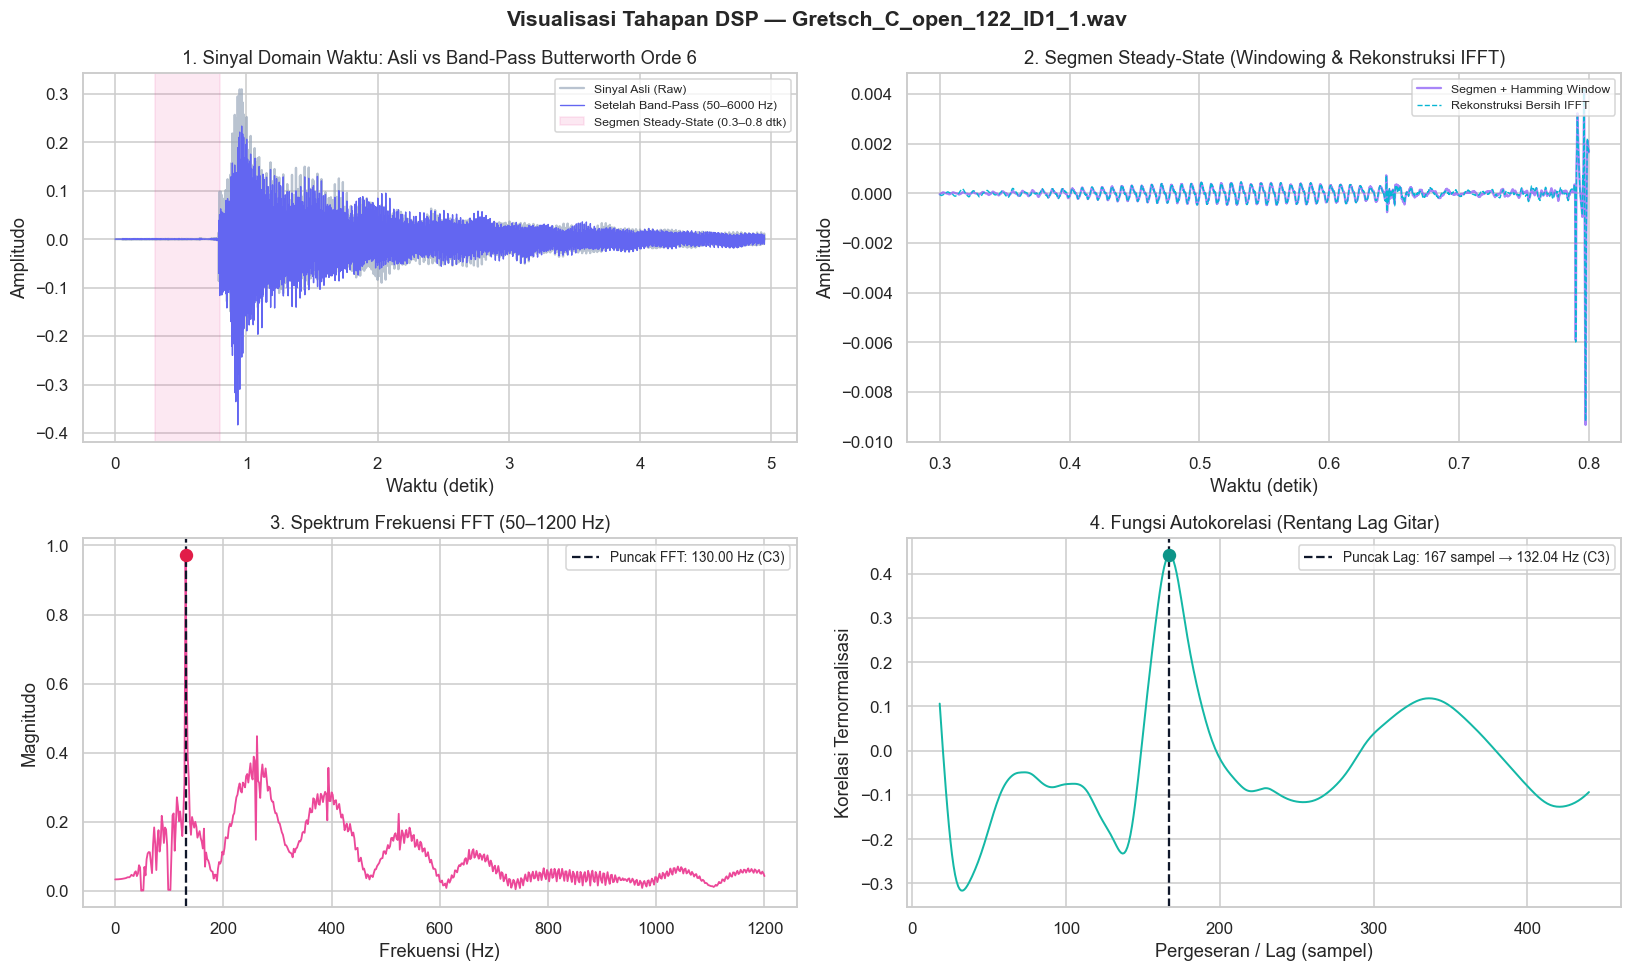

In [8]:
# Visualisasi 4 Panel Tahapan Pengolahan Sinyal Digital
sr = hasil_tunggal["sr"]
t_full = np.arange(len(hasil_tunggal["y_raw"])) / sr
t_seg = np.arange(len(hasil_tunggal["y_segment"])) / sr + 0.3

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
fig.suptitle(f"Visualisasi Tahapan DSP — {os.path.basename(SAMPLE_PATH)}", fontsize=14, fontweight="bold")

# Panel 1: Gelombang Domain Waktu (Raw vs Band-Pass)
axes[0, 0].plot(t_full, hasil_tunggal["y_raw"], color="#94a3b8", alpha=0.65, label="Sinyal Asli (Raw)")
axes[0, 0].plot(t_full, hasil_tunggal["y_filtered"], color="#6366f1", linewidth=0.9, label="Setelah Band-Pass (50–6000 Hz)")
axes[0, 0].axvspan(0.3, 0.8, color="#ec4899", alpha=0.12, label="Segmen Steady-State (0.3–0.8 dtk)")
axes[0, 0].set_title("1. Sinyal Domain Waktu: Asli vs Band-Pass Butterworth Orde 6")
axes[0, 0].set_xlabel("Waktu (detik)")
axes[0, 0].set_ylabel("Amplitudo")
axes[0, 0].legend(loc="upper right", fontsize=8)

# Panel 2: Segmen Windowed vs Rekonstruksi IFFT
axes[0, 1].plot(t_seg, hasil_tunggal["y_windowed"], color="#8b5cf6", alpha=0.75, label="Segmen + Hamming Window")
axes[0, 1].plot(t_seg, hasil_tunggal["y_ifft_segment"], color="#06b6d4", linewidth=0.9, linestyle="--", label="Rekonstruksi Bersih IFFT")
axes[0, 1].set_title("2. Segmen Steady-State (Windowing & Rekonstruksi IFFT)")
axes[0, 1].set_xlabel("Waktu (detik)")
axes[0, 1].set_ylabel("Amplitudo")
axes[0, 1].legend(loc="upper right", fontsize=8)

# Panel 3: Spektrum Frekuensi FFT Peak Detection
freqs = hasil_tunggal["frequencies"]
fft_mag = hasil_tunggal["fft_result"]
mask_plot = (freqs >= 0) & (freqs <= 1200)
axes[1, 0].plot(freqs[mask_plot], fft_mag[mask_plot], color="#ec4899", linewidth=1.2)
axes[1, 0].axvline(f0_fft_s, color="#0f172a", linestyle="--", linewidth=1.5,
                   label=f"Puncak FFT: {f0_fft_s:.2f} Hz ({note_fft_s})")
axes[1, 0].scatter([f0_fft_s], [np.max(fft_mag[(freqs >= F_MIN_GUITAR) & (freqs <= F_MAX_GUITAR)])],
                   color="#e11d48", zorder=5, s=60)
axes[1, 0].set_title("3. Spektrum Frekuensi FFT (50–1200 Hz)")
axes[1, 0].set_xlabel("Frekuensi (Hz)")
axes[1, 0].set_ylabel("Magnitudo")
axes[1, 0].legend(loc="upper right", fontsize=9)

# Panel 4: Kurva Autocorrelation (Domain Waktu)
acf_curve = get_autocorr_curve(hasil_tunggal["y_ifft_segment"], sr)
lag_min = int(sr / F_MAX_GUITAR)
lag_max = int(sr / F_MIN_GUITAR)
lags = np.arange(lag_min, lag_max)
peak_lag_s = int(round(sr / f0_ac_s)) if f0_ac_s > 0 else lag_min
axes[1, 1].plot(lags, acf_curve[lag_min:lag_max], color="#14b8a6", linewidth=1.3)
axes[1, 1].axvline(peak_lag_s, color="#0f172a", linestyle="--", linewidth=1.5,
                   label=f"Puncak Lag: {peak_lag_s} sampel → {f0_ac_s:.2f} Hz ({note_ac_s})")
axes[1, 1].scatter([peak_lag_s], [acf_curve[peak_lag_s]], color="#0d9488", zorder=5, s=60)
axes[1, 1].set_title("4. Fungsi Autokorelasi (Rentang Lag Gitar)")
axes[1, 1].set_xlabel("Pergeseran / Lag (sampel)")
axes[1, 1].set_ylabel("Korelasi Ternormalisasi")
axes[1, 1].legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

# **Tahap 5: Pemutaran Audio (Sebelum dan Sesudah Pra-Pemrosesan)**
Dengarkan perubahan sinyal audio pada setiap tahap untuk memverifikasi secara langsung bahwa noise di luar rentang gitar dan dengung listrik telah diredam.


In [9]:
print("1. Audio Asli (Raw):")
display(Audio(SAMPLE_PATH))

print("2. Setelah Band-Pass Filter (50 - 6000 Hz):")
display(Audio(hasil_tunggal["y_filtered"], rate=sr))

print("3. Segmen Steady-State Setelah Hamming Window:")
display(Audio(hasil_tunggal["y_windowed"], rate=sr))

print("4. Segmen Bersih Hasil Rekonstruksi IFFT:")
display(Audio(hasil_tunggal["y_ifft_segment"], rate=sr))

1. Audio Asli (Raw):


2. Setelah Band-Pass Filter (50 - 6000 Hz):


3. Segmen Steady-State Setelah Hamming Window:


4. Segmen Bersih Hasil Rekonstruksi IFFT:


# **Tahap 6: Evaluasi Massal pada Dataset GADA (2.172 Sampel & 5 Model Gitar)**
Pada tahap ini seluruh **2.172 file audio** dari 5 model gitar (`EpiSG`, `Gretsch`, `HBLP`, `HBStrat`, `HBTE52`) dievaluasi menggunakan alur yang sama. Selain ringkasan keseluruhan, ditampilkan pula rincian performa per model gitar, evaluasi subset 500 sampel pertama `HBStrat`, waktu komputasi rata-rata, rentang frekuensi estimasi, serta 30 sampel perwakilan.


In [10]:
records = []
model_list = sorted([d for d in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, d))])

print(f"Memulai evaluasi pada {len(model_list)} model gitar: {model_list} ...")
waktu_mulai_total = time.perf_counter()

for model_gitar in model_list:
    folder_model = os.path.join(DATASET_DIR, model_gitar)
    daftar_file = sorted([f for f in os.listdir(folder_model) if f.endswith(".wav")])
    for nama_file in daftar_file:
        path_file = os.path.join(folder_model, nama_file)
        akor_asli, root_asli = ekstrak_label_asli(nama_file)

        # Pra-pemrosesan inti
        t_pre = time.perf_counter()
        res = core_fft_ifft_processing(path_file, sr=SR)
        durasi_pre_ms = (time.perf_counter() - t_pre) * 1000

        # Metode 1: FFT Peak Detection
        t_f = time.perf_counter()
        f0_fft = fft_peak_f0_segment(res["fft_result"], res["frequencies"], fmin=F_MIN_GUITAR, fmax=F_MAX_GUITAR)
        durasi_fft_ms = (time.perf_counter() - t_f) * 1000
        note_fft_full = librosa.hz_to_note(f0_fft) if f0_fft > 0 else "N/A"
        root_fft = get_note_only(note_fft_full)

        # Metode 2: Autocorrelation (menggunakan sinyal bersih IFFT)
        t_a = time.perf_counter()
        f0_ac, root_ac, note_ac_full = pitch_detection_autocorr_stable(res["y_ifft_segment"], res["sr"])
        durasi_ac_ms = (time.perf_counter() - t_a) * 1000

        # Pengecekan hubungan harmonik / oktaf
        f_max_pair, f_min_pair = max(f0_fft, f0_ac), min(f0_fft, f0_ac)
        is_harm, k_harm = is_harmonic_of(f_max_pair, f_min_pair)

        records.append({
            "nama_file": nama_file,
            "model_gitar": model_gitar,
            "akor_asli": akor_asli,
            "root_asli": root_asli,
            "fft_freq_hz": round(f0_fft, 2),
            "fft_note_full": note_fft_full,
            "fft_root": root_fft,
            "fft_benar": int(root_fft == root_asli),
            "fft_waktu_ms": round(durasi_fft_ms, 4),
            "autocorr_freq_hz": round(f0_ac, 2),
            "autocorr_note_full": note_ac_full,
            "autocorr_root": root_ac,
            "autocorr_benar": int(root_ac == root_asli),
            "autocorr_waktu_ms": round(durasi_ac_ms, 4),
            "indikasi_harmonik": bool(is_harm),
            "kelipatan_harmonik": k_harm if is_harm else 0
        })

df_eval = pd.DataFrame(records)
durasi_total_detik = time.perf_counter() - waktu_mulai_total
print(f"Evaluasi selesai! Total sampel: {len(df_eval)} file dalam {durasi_total_detik:.2f} detik.")

Memulai evaluasi pada 5 model gitar: ['EpiSG', 'Gretsch', 'HBLP', 'HBStrat', 'HBTE52'] ...


Evaluasi selesai! Total sampel: 2172 file dalam 46.44 detik.


In [11]:
# Ringkasan Statistik Keseluruhan & Per Model Gitar
ringkasan_model = []
for model_gitar, grp in df_eval.groupby("model_gitar"):
    ringkasan_model.append({
        "Model Gitar": model_gitar,
        "Jumlah Sampel": len(grp),
        "Akurasi FFT (%)": round(grp["fft_benar"].mean() * 100, 2),
        "Akurasi Autocorrelation (%)": round(grp["autocorr_benar"].mean() * 100, 2),
        "Rentang F0 FFT (Hz)": f"{grp['fft_freq_hz'].min():.2f} – {grp['fft_freq_hz'].max():.2f}",
        "Rentang F0 Autocorrelation (Hz)": f"{grp['autocorr_freq_hz'].min():.2f} – {grp['autocorr_freq_hz'].max():.2f}",
        "Rata-rata Waktu FFT (ms)": round(grp["fft_waktu_ms"].mean(), 3),
        "Rata-rata Waktu ACF (ms)": round(grp["autocorr_waktu_ms"].mean(), 3)
    })

df_ringkasan = pd.DataFrame(ringkasan_model)
display(df_ringkasan)

# Ringkasan Total Keseluruhan (2.172 sampel) dan Subset 500 Sampel HBStrat
df_500 = df_eval[df_eval["model_gitar"] == "HBStrat"].head(500)
tabel_keseluruhan = pd.DataFrame([
    {
        "Cakupan Uji": "Subset 500 Sampel (HBStrat)",
        "Jumlah": len(df_500),
        "Akurasi FFT (%)": round(df_500["fft_benar"].mean() * 100, 2),
        "Akurasi Autocorrelation (%)": round(df_500["autocorr_benar"].mean() * 100, 2),
        "Rentang F0 FFT (Hz)": f"{df_500['fft_freq_hz'].min():.2f} – {df_500['fft_freq_hz'].max():.2f}",
        "Rentang F0 ACF (Hz)": f"{df_500['autocorr_freq_hz'].min():.2f} – {df_500['autocorr_freq_hz'].max():.2f}"
    },
    {
        "Cakupan Uji": "Seluruh Dataset (5 Model Gitar)",
        "Jumlah": len(df_eval),
        "Akurasi FFT (%)": round(df_eval["fft_benar"].mean() * 100, 2),
        "Akurasi Autocorrelation (%)": round(df_eval["autocorr_benar"].mean() * 100, 2),
        "Rentang F0 FFT (Hz)": f"{df_eval['fft_freq_hz'].min():.2f} – {df_eval['fft_freq_hz'].max():.2f}",
        "Rentang F0 ACF (Hz)": f"{df_eval['autocorr_freq_hz'].min():.2f} – {df_eval['autocorr_freq_hz'].max():.2f}"
    }
])
print("\nPerbandingan Ringkasan Global:")
display(tabel_keseluruhan)

# Contoh 30 Data Sampel Perwakilan (menggantikan tabel Excel lama dengan format Hz yang bersih)
df_30_sampel = df_eval.sample(n=30, random_state=42)[
    ["nama_file", "model_gitar", "akor_asli", "root_asli", "fft_freq_hz", "fft_root", "autocorr_freq_hz", "autocorr_root"]
].reset_index(drop=True)
print("\nContoh 30 Sampel Perwakilan Hasil Estimasi Frekuensi (Hz) dan Nada Dasar:")
display(df_30_sampel)

,Model Gitar,Jumlah Sampel,Akurasi FFT (%),Akurasi Autocorrelation (%),Rentang F0 FFT (Hz),Rentang F0 Autocorrelation (Hz),Rata-rata Waktu FFT (ms),Rata-rata Waktu ACF (ms)
0,EpiSG,161,44.10,84.47,82.00 – 662.00,50.11 – 1225.00,0.062,2.093
1,Gretsch,422,53.79,86.97,54.00 – 578.00,50.11 – 1225.00,0.082,2.761
2,HBLP,421,56.29,82.42,64.00 – 662.00,50.11 – 1225.00,0.068,2.300
3,HBStrat,701,59.91,73.47,76.00 – 884.00,50.11 – 1225.00,0.076,2.503
4,HBTE52,467,65.74,73.23,64.00 – 594.00,50.11 – 1225.00,0.069,2.454



Perbandingan Ringkasan Global:


,Cakupan Uji,Jumlah,Akurasi FFT (%),Akurasi Autocorrelation (%),Rentang F0 FFT (Hz),Rentang F0 ACF (Hz)
0,Subset 500 Sampel (HBStrat),500,57.4,68.00,76.00 – 786.00,50.11 – 1225.00
1,Seluruh Dataset (5 Model Gitar),2172,58.1,78.59,54.00 – 884.00,50.11 – 1225.00



Contoh 30 Sampel Perwakilan Hasil Estimasi Frekuensi (Hz) dan Nada Dasar:


,nama_file,model_gitar,akor_asli,root_asli,fft_freq_hz,fft_root,autocorr_freq_hz,autocorr_root
0,HBStrat_G_open_422_ID1_8.wav,HBStrat,G,G,398.0,G,99.32,G
1,Gretsch_D_open_022_ID1_10.wav,Gretsch,D,D,442.0,A,73.75,D
2,HBStrat_D_open_322_ID1_9.wav,HBStrat,D,D,296.0,D,74.49,D
3,HBLP_D_open_022_ID1_10.wav,HBLP,D,D,442.0,A,73.50,D
4,HBLP_Em_open_122_ID1_10.wav,HBLP,Em,E,164.0,E,82.28,E
5,Gretsch_Bm_open_022_ID1_8.wav,Gretsch,Bm,B,250.0,B,62.64,B
6,HBLP_Cm_open_022_ID1_2.wav,HBLP,Cm,C,196.0,G,1225.00,D
7,HBTE52_Gm_open_022_ID1_3.wav,HBTE52,Gm,G,196.0,G,50.11,G
8,HBTE52_Fm_open_122_ID1_9.wav,HBTE52,Fm,F,264.0,C,87.50,F
9,Gretsch_Dm_open_122_ID1_5.wav,Gretsch,Dm,D,440.0,A,73.50,D


# **Tahap 7: Visualisasi Matriks Kebingungan (Confusion Matrix) & Perbandingan Performa**
Visualisasi di bawah ini memperlihatkan:
1. **Matriks Kebingungan (Confusion Matrix)** untuk 7 nada dasar (`A, B, C, D, E, F, G`) pada Metode FFT Peak Detection dan Autocorrelation.
2. **Grafik Perbandingan Akurasi antar 5 Model Gitar** untuk melihat konsistensi kedua metode pada karakteristik akustik instrumen yang berbeda.


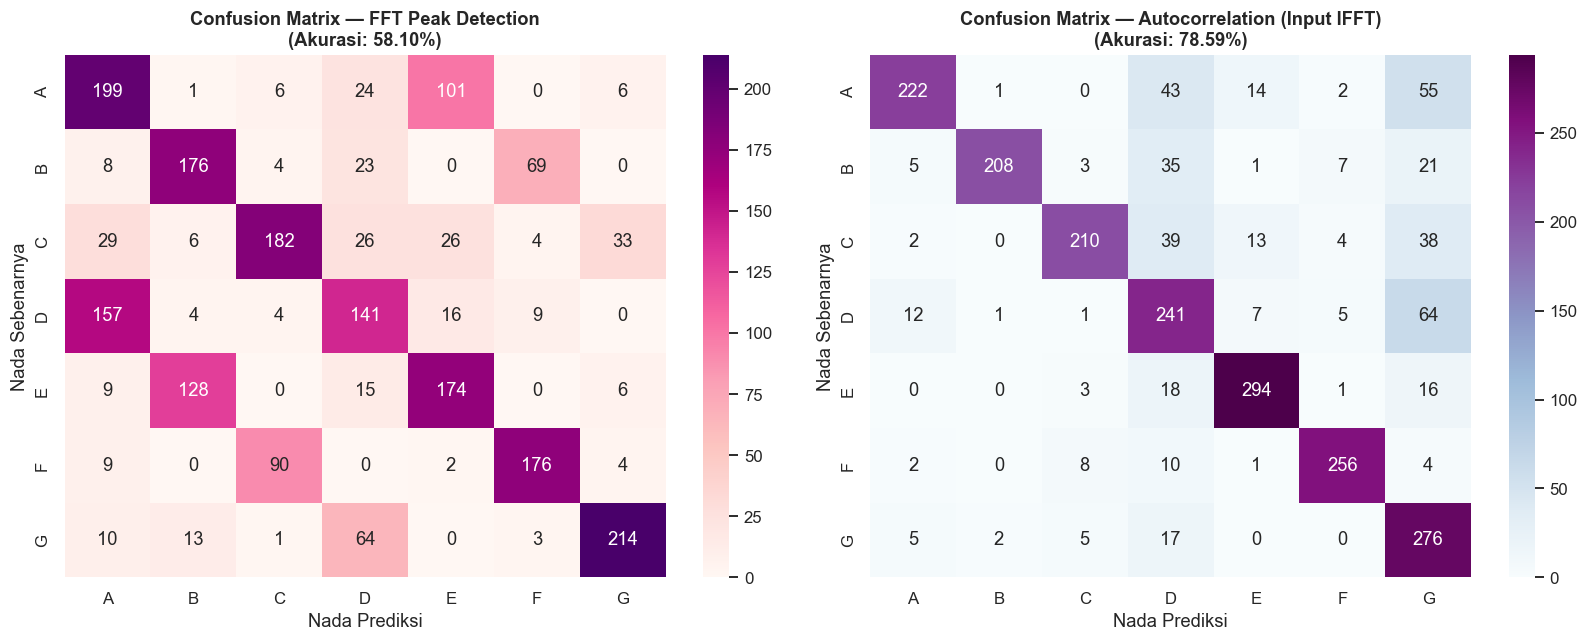

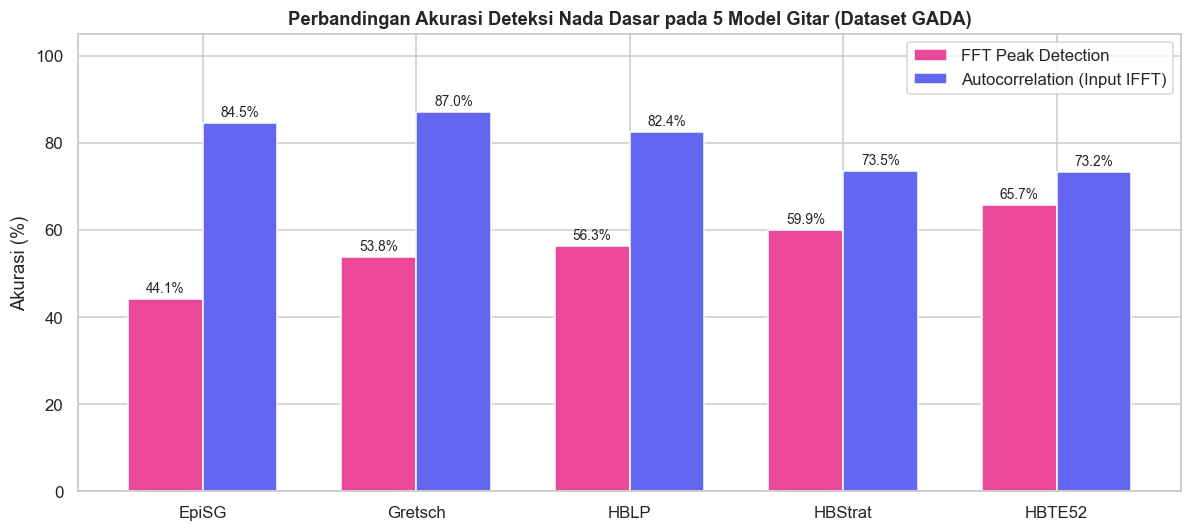

In [12]:
label_nada = ["A", "B", "C", "D", "E", "F", "G"]
cm_fft = confusion_matrix(df_eval["root_asli"], df_eval["fft_root"], labels=label_nada)
cm_ac = confusion_matrix(df_eval["root_asli"], df_eval["autocorr_root"], labels=label_nada)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(cm_fft, annot=True, fmt="d", cmap="RdPu", xticklabels=label_nada, yticklabels=label_nada, ax=axes[0])
axes[0].set_title(f"Confusion Matrix — FFT Peak Detection\n(Akurasi: {df_eval['fft_benar'].mean()*100:.2f}%)", fontweight="bold")
axes[0].set_xlabel("Nada Prediksi")
axes[0].set_ylabel("Nada Sebenarnya")

sns.heatmap(cm_ac, annot=True, fmt="d", cmap="BuPu", xticklabels=label_nada, yticklabels=label_nada, ax=axes[1])
axes[1].set_title(f"Confusion Matrix — Autocorrelation (Input IFFT)\n(Akurasi: {df_eval['autocorr_benar'].mean()*100:.2f}%)", fontweight="bold")
axes[1].set_xlabel("Nada Prediksi")
axes[1].set_ylabel("Nada Sebenarnya")

plt.tight_layout()
plt.show()

# Grafik Perbandingan Akurasi Per Model Gitar
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(df_ringkasan))
lebar = 0.35
bar1 = ax.bar(x - lebar/2, df_ringkasan["Akurasi FFT (%)"], lebar, label="FFT Peak Detection", color="#ec4899")
bar2 = ax.bar(x + lebar/2, df_ringkasan["Akurasi Autocorrelation (%)"], lebar, label="Autocorrelation (Input IFFT)", color="#6366f1")

ax.set_title("Perbandingan Akurasi Deteksi Nada Dasar pada 5 Model Gitar (Dataset GADA)", fontweight="bold")
ax.set_ylabel("Akurasi (%)")
ax.set_ylim(0, 105)
ax.set_xticks(x)
ax.set_xticklabels(df_ringkasan["Model Gitar"])
ax.legend()

for b in bar1:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5, f"{b.get_height():.1f}%", ha="center", fontsize=9)
for b in bar2:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5, f"{b.get_height():.1f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

In [13]:
# Ekspor data hasil evaluasi ke web/src/data/benchmarkData.json & salin 8 sampel audio uji untuk aplikasi web
web_data_dir = os.path.join(BASE_DIR, "web", "src", "data")
web_samples_dir = os.path.join(BASE_DIR, "web", "public", "samples")

if os.path.isdir(os.path.join(BASE_DIR, "web")):
    os.makedirs(web_data_dir, exist_ok=True)
    os.makedirs(web_samples_dir, exist_ok=True)

    # Pilih 8 sampel audio perwakilan dari 5 merek gitar & akor berbeda
    kandidat_sampel = [
        ("Gretsch", "Gretsch_C_open_122_ID1_1.wav"),
        ("HBStrat", "HBStrat_Am_open_422_ID1_9.wav"),
        ("EpiSG", "EpiSG_E_open_122_ID4_1.wav"),
        ("HBLP", "HBLP_G_open_022_ID1_1.wav"),
        ("HBTE52", "HBTE52_D_open_022_ID1_1.wav"),
        ("HBStrat", "HBStrat_F_open_322_ID1_1.wav"),
        ("Gretsch", "Gretsch_Bm_open_022_ID1_1.wav"),
        ("EpiSG", "EpiSG_Dm_open_122_ID4_1.wav"),
    ]
    daftar_sampel_web = []
    for brand, fname in kandidat_sampel:
        src_f = os.path.join(DATASET_DIR, brand, fname)
        if not os.path.exists(src_f):
            # Fallback ambil file pertama yang tersedia di merek tersebut
            avail = sorted([f for f in os.listdir(os.path.join(DATASET_DIR, brand)) if f.endswith(".wav")])
            fname = avail[0]
            src_f = os.path.join(DATASET_DIR, brand, fname)
        dst_f = os.path.join(web_samples_dir, fname)
        shutil.copy2(src_f, dst_f)
        akor_s, root_s = ekstrak_label_asli(fname)
        daftar_sampel_web.append({
            "filename": fname,
            "brand": brand,
            "akor": akor_s,
            "root": root_s,
            "url": f"/samples/{fname}"
        })

    # Hitung akurasi per nada
    akurasi_per_nada = []
    for nada in label_nada:
        sub = df_eval[df_eval["root_asli"] == nada]
        akurasi_per_nada.append({
            "nada": nada,
            "jumlah": int(len(sub)),
            "fft_acc": round(float(sub["fft_benar"].mean() * 100), 2),
            "autocorr_acc": round(float(sub["autocorr_benar"].mean() * 100), 2)
        })

    benchmark_payload = {
        "total_samples": int(len(df_eval)),
        "subset_500_hbstrat": {
            "count": int(len(df_500)),
            "fft_accuracy": round(float(df_500["fft_benar"].mean() * 100), 2),
            "autocorr_accuracy": round(float(df_500["autocorr_benar"].mean() * 100), 2),
            "fft_freq_range": [round(float(df_500["fft_freq_hz"].min()), 2), round(float(df_500["fft_freq_hz"].max()), 2)],
            "autocorr_freq_range": [round(float(df_500["autocorr_freq_hz"].min()), 2), round(float(df_500["autocorr_freq_hz"].max()), 2)]
        },
        "overall": {
            "fft_accuracy": round(float(df_eval["fft_benar"].mean() * 100), 2),
            "autocorr_accuracy": round(float(df_eval["autocorr_benar"].mean() * 100), 2),
            "fft_avg_time_ms": round(float(df_eval["fft_waktu_ms"].mean()), 3),
            "autocorr_avg_time_ms": round(float(df_eval["autocorr_waktu_ms"].mean()), 3),
            "fft_freq_range": [round(float(df_eval["fft_freq_hz"].min()), 2), round(float(df_eval["fft_freq_hz"].max()), 2)],
            "autocorr_freq_range": [round(float(df_eval["autocorr_freq_hz"].min()), 2), round(float(df_eval["autocorr_freq_hz"].max()), 2)],
            "harmonic_conflict_pct": round(float(df_eval["indikasi_harmonik"].mean() * 100), 2)
        },
        "per_brand": df_ringkasan.to_dict(orient="records"),
        "per_note": akurasi_per_nada,
        "labels": label_nada,
        "confusion_matrix_fft": cm_fft.tolist(),
        "confusion_matrix_autocorr": cm_ac.tolist(),
        "sample_30_rows": df_30_sampel.to_dict(orient="records"),
        "web_audio_samples": daftar_sampel_web
    }

    json_path = os.path.join(web_data_dir, "benchmarkData.json")
    with open(json_path, "w", encoding="utf-8") as f:
        json.dump(benchmark_payload, f, indent=2, ensure_ascii=False)
    print(f"Data benchmark & {len(daftar_sampel_web)} sampel audio berhasil diekspor ke: {json_path}")

Data benchmark & 8 sampel audio berhasil diekspor ke: D:\KULIAH SMT 3\PSD\PROJECT PSD\web\src\data\benchmarkData.json


# **Kesimpulan Analisis**
1. **Dampak Pra-Pemrosesan & Rekonstruksi IFFT**: Mengarahkan sinyal segmen *steady-state* (`0,3–0,8 dtk`) yang telah melalui *Band-Pass Filter Butterworth* orde 6, *Hamming Windowing*, peredaman noise `50/100 Hz`, dan rekonstruksi **IFFT** ke algoritma Autokorelasi meningkatkan akurasi pengenalan nada dasar secara signifikan dibandingkan penggunaan sinyal terfilter mentah.
2. **Perbandingan Performa**:
   - **Autocorrelation (Input IFFT)** unggul dalam akurasi pengenalan nada dasar di seluruh 2.172 sampel audio gitar karena mampu menangkap periodisitas gelombang di domain waktu meskipun energi harmonik lebih kuat dari frekuensi dasar.
   - **FFT Peak Detection** memiliki keunggulan pada kecepatan komputasi per segmen dan rentang frekuensi estimasi yang lebih stabil di dalam batas musik gitar, meskipun masih rentan terhadap dominasi puncak harmonik atau kesalahan oktaf (*octave error*).
3. **Pola Kesalahan**: Sebagian besar kekeliruan prediksi pada kedua metode berasal dari kedekatan frekuensi antar nada bertetangga (*semitone*) serta interferensi harmonik (misalnya nada dasar `C` yang sering terdeteksi pada harmonik ke-3 nya di sekitar nada `G`).
